In [1]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Make a violin plot for the analysis of the interactions
#Remember that it is important: Where is my storage dir? Where is my result dir? How many folders do I have?

folder_path= '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_interactions/stabilizers/pose_1/processed'
res_path= '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_interactions/compounds_filtered/pose_1'

In [3]:
#Here we want to work with the sum of the interactions, the positions are not so relevant, we look for differences!
#Since we already created a binary dataset, now we just want the positions were we have a 1.

#1. Transpose the tabel for the columns to be the interacttion types and the rows the rows, ___.T
#2. Then filter it by 1 and then save to csv: _______[_______.any(axis=1)]
#Remember to select the right name to save

#Here maybe you do not need to save the file to csv yet


for file in os.listdir(folder_path):               
    file_path = os.path.join(folder_path, file)
    
    if file.split('.')[-1] != 'csv':
        continue

    compounds= pd.read_csv(file_path).T
        
    filtered_compound = compounds[compounds.any(axis=1)]

    csv_file_name = file.split('.')[0] +'_' + 'filtered'+'.csv'
    #csv_file_name = file.split('.')[0] + '_' + 'weak'+'_' + 'filtered'+'.csv'
    result_dir = os.path.join(res_path, csv_file_name)
    filtered_compound.to_csv(result_dir)

In [4]:
print(compounds)

                   0            1
feature  hydrophobic  waterbridge
0                  0            0
1                  0            0
2                  0            0
3                  0            0
...              ...          ...
448                0            0
449                0            0
450                0            0
451                0            0
452                0            0

[454 rows x 2 columns]


In [5]:
#Sum the interactions
#Now we want our data to all have the same columns, so #Add the column names that are not included

#Define the directory

folder_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_interactions/compounds_filtered/pose_1/'
res_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables'

#Defining my columns 

all_columns = ['hydrophobic', 'pistack', 'pication_ligand_ring', 'pication_ligand_charge', 'halogen_ligand_donnor', 'hbond_ligand_acceptor', 'hbond_ligand_donnor',
           'waterbridge','ionic_ligand_positive', 'ionic_ligand_negative', 'metal']



#Matrix
matrix_rows = []
file_names = []

    
for file in os.listdir(folder_path):               
    file_path = os.path.join(folder_path, file)
        
    if file.split('.')[-1] != 'csv':
        continue
        
    compounds= pd.read_csv(file_path, header=1) #Skip the first row for the summation

    
    #New data frame that takes the information of the compounds
    df_matrix = compounds.reindex(columns=all_columns, fill_value=0) #Add the column names that are not included

    row_vector =df_matrix.sum(axis=0)
    matrix_rows.append(row_vector)
    #Add the created datat to your empty data set matrix_rows
    
    file_names.append(file)
    #Add the file name as data set to be added in the rows to be able to tract what file we working with

        
#Convert your data into a new matrix
matrix = pd.DataFrame(matrix_rows, index=file_names)

#print(matrix)


#matrix.to_csv('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/matrix_interactions_pose_1')
    

In [6]:
#Table sorting
#We want to have a special table layout and therefore we modify it
#1. Store the column names 
#2. Now create a column that is called 'key_split'
#This will have our column names and extract the number of the compund aka. compund name
#3. Make the extracted numbers from a string to a number
#This way we can sort them! And organize our compounds
#4.Sort your compunds, this time we used sort_values instead of sorted()



table_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/matrix_old'
res_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables'

for csv_file in os.listdir(table_path):               
    csv_path = os.path.join(table_path, csv_file)
        
    if csv_file.split('.')[-1] != 'csv':
       continue
        
    compounds= pd.read_csv(csv_path)

    col_name= compounds.columns[0]

    compounds['key_split'] =compounds[col_name].str.split('_').str[4]
    compounds['key_split'] = pd.to_numeric(compounds['key_split'], errors='coerce')


    compounds_sorted = compounds.sort_values(by='key_split', ascending=True)


    #print(compounds_sorted)

    csv_file_name = 'matrix_interactions_sorted_pose_' + csv_file.split('_')[3]+'.csv'
    res_dir = os.path.join(res_path, csv_file_name)
    compounds_sorted.to_csv(res_dir, index= False) #Add indexing = false so that you get no extra colum with passed indexes
            

  

In [7]:
compounds_sorted

,Unnamed: 0,hydrophobic,pistack,pication_ligand_ring,pication_ligand_charge,halogen_ligand_donnor,hbond_ligand_acceptor,hbond_ligand_donnor,waterbridge,ionic_ligand_positive,ionic_ligand_negative,metal,key_split
19,dock_smina_PAH_6N1K_0_pose_3_stabilizer_filter...,4.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0
33,dock_smina_PAH_6N1K_0_pose_3_destabilizer_filt...,4.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0
40,dock_smina_PAH_6N1K_1_pose_3_destabilizer_filt...,2.0,1.0,0.0,0.0,0.0,3.0,1.0,0.0,0.0,0.0,0.0,1
12,dock_smina_PAH_6N1K_1_pose_3_stabilizer_filter...,7.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
127,dock_smina_PAH_6N1K_1_pose_3_no_stabilizer_str...,5.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
243,dock_smina_PAH_6N1K_2576_pose_3_no_stabilizer_...,6.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2576
158,dock_smina_PAH_6N1K_2593_pose_3_no_stabilizer_...,3.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2593
189,dock_smina_PAH_6N1K_2599_pose_3_no_stabilizer_...,4.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2599
205,dock_smina_PAH_6N1K_2608_pose_3_no_stabilizer_...,7.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,2608


In [8]:
#Summation by pose
#Why do we sum the poses? One pose may ignore or miss one fundamental interaction, therefore, if we want to identify the differences,
#we need to sum all our poses and not miss any interaction!

#1. Iterate through your files and create an empty data set to store them
#2. Skip the first column for the sumation! You cannot sum names!
#3. Append the datat to your empty data set, this is the way you want to sum different csv files!
#4. Extract a the first column with the file names 
#5. Concat the sumation and the file names

table_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/sorted_matrix'

column_names= '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/sorted_matrix/matrix_interactions_sorted_pose_1.csv'

df_compounds= []

for csv_file in os.listdir(table_path):               
    csv_path = os.path.join(table_path, csv_file)
        
    if csv_file.split('.')[-1] != 'csv':
       continue
        
    compounds= pd.read_csv(csv_path)

    df_compound = compounds.iloc[:,1:] #all rows and skip first colum
    
    df_compounds.append(df_compound)

    
compounds_sum= sum(df_compounds)
    
first_col = pd.read_csv(column_names).iloc[:,0] #first colum
    
result = pd.concat([first_col, compounds_sum], axis=1)

    
#print (result)
    
result.to_csv('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/sorted_matrix/matrix_sum.csv', index= False)

In [51]:
#Add the clases
#Now we need a new column only with the class name of each compound for making the filtering process easier later
#1. Define your classes

sum_path = '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/sorted_matrix/matrix_sum.csv'

compound_labels = ['stabilizer', 'destabilizer', 'strong', 'weak']

compounds = pd.read_csv(sum_path)
compounds["ionic_ligand_total"] = (compounds["ionic_ligand_positive"] + compounds["ionic_ligand_negative"])

compounds["pication_total"] = (compounds["pication_ligand_charge"] + compounds["pication_ligand_ring"])

compounds["hbond_total"] = (compounds["hbond_ligand_acceptor"] + compounds["hbond_ligand_donnor"])

first_col = compounds.iloc[:, 0]
compounds["label"] = first_col.str.split("_").str[-2]
#Change weak interaction into 'strong' eigentlich wäre besser no-effect
compounds.loc[compounds["label"] == "weak", "label"] = "strong"



# 1. Drop the second column (index = 1)
compounds = compounds.drop(compounds.columns[1], axis=1)

# 2. Move "label" column to the end
compounds = compounds[[c for c in compounds.columns if c != "label"] + ["label"]]



print(compounds)



compounds.to_csv('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/sorted_matrix/matrix_sum_labels_clean.csv', index = None)


                                            Unnamed: 0  halogen_ligand_donnor  \
0    dock_smina_PAH_6N1K_0_pose_1_stabilizer_filter...                    0.0   
1    dock_smina_PAH_6N1K_0_pose_1_destabilizer_filt...                    0.0   
2    dock_smina_PAH_6N1K_1_pose_1_no_stabilizer_str...                    0.0   
3    dock_smina_PAH_6N1K_1_pose_1_stabilizer_filter...                    0.0   
4    dock_smina_PAH_6N1K_1_pose_1_destabilizer_filt...                    0.0   
..                                                 ...                    ...   
243  dock_smina_PAH_6N1K_2586_pose_1_no_stabilizer_...                    0.0   
244  dock_smina_PAH_6N1K_2596_pose_1_no_stabilizer_...                    0.0   
245  dock_smina_PAH_6N1K_2605_pose_1_no_stabilizer_...                    7.0   
246  dock_smina_PAH_6N1K_2610_pose_1_no_stabilizer_...                    0.0   
247  dock_smina_PAH_6N1K_2613_pose_1_no_stabilizer_...                    0.0   

     hbond_ligand_acceptor 

/tmp/ipykernel_471/1129733793.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.violinplot(data= matrix, x="label", y="halogen_ligand_donnor", inner="point", palette='plasma')


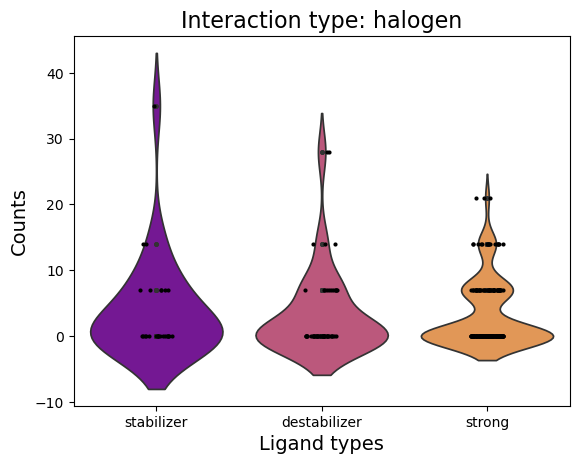

In [55]:
#Violinplot

#After the data preparation we can read our datat set and make our violin plot
#Use the ax=sns.violinplot() function to generate your plot
#x= is the category/column used to filter your datat
#y= is within that category, what do you class you want to use for the plot

#Just add the name "label" to your last column to finish data preparation

#For gradient color and color selection
#https://www.practicalpythonfordatascience.com/ap_seaborn_palette

matrix_path= '/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_tables/sorted_matrix/matrix_sum_labels_clean.csv'

matrix= pd.read_csv(matrix_path)

last_col = matrix.columns[-1]          # Get the last column, without it having a name
matrix.rename(columns={last_col: 'label'}, inplace=True)




ax=sns.violinplot(data= matrix, x="label", y="halogen_ligand_donnor", inner="point", palette='plasma')

# Overlay with jittered points
sns.stripplot(
    data=matrix,
    x="label",
    y="halogen_ligand_donnor",
    color='k',         # color of points
    size=3,            # size of points
    jitter=True,       # apply jitter
    ax=ax
)

ax.set_title('Interaction type: halogen', fontsize=16)
ax.set_xlabel('Ligand types', fontsize=14)
ax.set_ylabel('Counts', fontsize=14)
#ax.set_ylim(bottom=0)

plt.savefig('/projectbig/jupyternotebook/jrivera/output/pocket_results/ligand_figures/sum/compounds_sum_by_halogen')
plt.show()